# 08 - Challenger models: XGBoost and LightGBM vs the scorecard

**Goal.** Check whether gradient boosting gives a materially better PD model than the Phase 1 scorecard,
on exactly the same data, and decide which model should be the champion.

| Part | Content |
|---|---|
| A | Champion: load the validated scorecard, show its training code, prove it is reproducible |
| B | Challengers: tune XGBoost and LightGBM with cross-validation on the development set only |
| C | Comparison on the hold-out set: AUC / Gini / KS, paired bootstrap, calibration, rank ordering, approval vs bad rate, PSI / CSI, SHAP |
| D | Decision against a rule fixed **before** looking at the hold-out results |

All logic lives in `src/` (`champion.py`, `challengers.py`, `comparison.py`) and in `train.py`.
`train.py` runs the same steps end to end and writes a versioned Excel report to `runs/<run_id>/`;
this notebook carries the narrative and the reasoning.

In [1]:
import sys, json, inspect
sys.path.insert(0, "../src")
sys.path.insert(0, "..")   # for train.py

from pathlib import Path
for _p in ("../outputs/figures", "../outputs/metrics", "../outputs/models"):
    Path(_p).mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
from IPython.display import Image, display

import comparison as cmp
from champion import load_champion
from challengers import FEATURES, TreeModel, tune, best_params, fit_final
from data_processing import SEED
import train   # train_scorecard(), check_refit()

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

FIG = Path("../outputs/figures")
dev = pd.read_csv("../data/processed/dev.csv", index_col="id")
hold = pd.read_csv("../data/processed/holdout.csv", index_col="id")
y_dev, y_hold = dev["target"].to_numpy(), hold["target"].to_numpy()
print(f"Development: {len(dev):,} rows, bad rate {y_dev.mean():.2%} | Hold-out: {len(hold):,} rows, bad rate {y_hold.mean():.2%}")

Development: 104,987 rows, bad rate 6.69% | Hold-out: 45,012 rows, bad rate 6.68%


## Part A - Champion: the Phase 1 scorecard

The champion is **loaded** from the specs saved in notebooks 04-06, not retrained. That way the model in this
comparison is exactly the one validated in notebook 07 (hold-out AUC 0.860), and the numbers in the README
stay valid.

In [2]:
champion = load_champion("../outputs/scorecard")
auc_saved = pd.read_csv("../outputs/metrics/holdout_discrimination.csv", index_col=0).loc["hold-out", "auc"]
auc_now = cmp.discrimination_metrics(y_hold, champion.predict_pd(hold))["auc"]
print(f"Hold-out AUC  notebook 07 = {auc_saved:.6f} | reloaded scorecard = {auc_now:.6f}")
assert np.isclose(auc_saved, auc_now)
print("Variables:", champion.features)

Hold-out AUC  notebook 07 = 0.859608 | reloaded scorecard = 0.859608
Variables: ['revolving_util', 'age', 'n_30_59_late', 'n_60_89_late', 'n_90_late', 'debt_ratio', 'n_open_lines', 'n_real_estate', 'n_dependents']


### The training code of the scorecard

For transparency, the full training logic of notebooks 04-06 is kept in one function, `train_scorecard()` in
`train.py`. It is **not** used for scoring. It only runs when asked (`python train.py --refit-scorecard`), or below
as a reproducibility check.

In [3]:
print("BINNING_CONFIG =", json.dumps(train.BINNING_CONFIG, indent=2), "\n")
print(inspect.getsource(train.train_scorecard))

BINNING_CONFIG = {
  "revolving_util": [
    "increasing_risk",
    0.02
  ],
  "age": [
    "decreasing_risk",
    0.05
  ],
  "n_30_59_late": [
    "increasing_risk",
    0.01
  ],
  "n_60_89_late": [
    "increasing_risk",
    0.01
  ],
  "n_90_late": [
    "increasing_risk",
    0.01
  ],
  "debt_ratio": [
    "increasing_risk",
    0.05
  ],
  "monthly_income": [
    "decreasing_risk",
    0.05
  ],
  "n_open_lines": [
    "decreasing_risk",
    0.01
  ],
  "n_real_estate": [
    "free",
    0.01
  ],
  "n_dependents": [
    "increasing_risk",
    0.01
  ]
} 

def train_scorecard(dev: pd.DataFrame) -> dict:
    """WoE binning -> variable selection -> logistic regression -> PDO scaling.

    Input: the CLEANED development set. Returns the three specs that Phase 1 saved in
    outputs/scorecard/ (binning_spec, model_spec, scorecard_spec).
    """
    y = dev["target"]

    # Step 1 (notebook 04): coarse classing with business-driven monotonic WoE.
    #   Bins are learned on the dev

In [4]:
# Reproducibility check: retrain from the cleaned development set and compare with the saved coefficients
refit_check = train.check_refit(train.train_scorecard(dev))
display(refit_check)
assert refit_check["match"].all()
print("OK: the training code reproduces the saved scorecard exactly")

,term,saved,refit,abs_diff,match
0,intercept,-2.605756,-2.605756,0.000000e+00,True
1,revolving_util,-0.598639,-0.598639,1.110223e-16,True
2,age,-0.413516,-0.413516,0.000000e+00,True
3,n_30_59_late,-0.484659,-0.484659,0.000000e+00,True
4,n_60_89_late,-0.370899,-0.370899,5.551115e-17,True
5,n_90_late,-0.534108,-0.534108,0.000000e+00,True
6,debt_ratio,-0.907913,-0.907913,0.000000e+00,True
7,n_open_lines,-0.104758,-0.104758,6.938894e-17,True
8,n_real_estate,-0.670754,-0.670754,0.000000e+00,True
9,n_dependents,-0.227924,-0.227924,5.551115e-17,True


OK: the training code reproduces the saved scorecard exactly


## Part B - Challengers: XGBoost and LightGBM

**Design rules (so the comparison is fair and the PD stays a PD):**

1. **Same data.** Same 70/30 split (seed 42) and the same deterministic `clean()`. Inputs are the 10 original
   columns; no WoE and no derived features. Trees need no binning, and missing values are handled natively:
   each split learns on which side NaN rows go.
2. **No class weights, no SMOTE.** Up-weighting bads would inflate every PD. The scorecard was built without them,
   so the challengers are too.
3. **The hold-out set is untouched until Part C.** Hyperparameters are chosen by 5-fold stratified CV on the
   development set (random search, 20 trials per model). Early stopping uses log loss on each fold's own
   validation part, which is still development data.
4. **Final model** = refit on the whole development set with the best parameters and
   `n_estimators` = mean best iteration across the 5 folds.

Why log loss for early stopping but AUC to rank trials? Log loss is a proper scoring rule, so stopping on it
protects the probability level; AUC is the main ranking metric a bank reports.

In [5]:
N_ITER = 20   # same as the default of train.py
cv_xgb = tune("xgboost", dev[FEATURES], dev["target"], n_iter=N_ITER, seed=SEED)
cv_xgb.head().round(4)

[xgboost] trial  1/20  CV AUC 0.8635 +/- 0.0064  trees 1586  (36.2s)


[xgboost] trial  2/20  CV AUC 0.8648 +/- 0.0059  trees  154  (8.3s)


[xgboost] trial  3/20  CV AUC 0.8649 +/- 0.0057  trees  423  (14.2s)


[xgboost] trial  4/20  CV AUC 0.8638 +/- 0.0057  trees  123  (7.5s)


[xgboost] trial  5/20  CV AUC 0.8647 +/- 0.0057  trees 1704  (44.6s)


[xgboost] trial  6/20  CV AUC 0.8651 +/- 0.0056  trees  414  (15.3s)


... (11 outputs left out)

[xgboost] trial 18/20  CV AUC 0.8651 +/- 0.0058  trees  542  (19.5s)


[xgboost] trial 19/20  CV AUC 0.8649 +/- 0.0057  trees  427  (15.0s)


[xgboost] trial 20/20  CV AUC 0.8653 +/- 0.0057  trees  656  (25.6s)


,trial,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,reg_lambda,gamma,cv_auc_mean,cv_auc_std,cv_logloss_mean,best_iter_mean,seconds
0,19,5,0.0110,13.6990,0.7319,0.6578,0.1730,1.1753,0.8653,0.0057,0.1779,656,25.6
1,9,5,0.0130,34.5156,0.7884,0.8261,5.7582,1.2694,0.8652,0.0058,0.1778,632,22.9
2,13,4,0.0123,45.9378,0.7848,0.6645,1.4221,0.3046,0.8652,0.0059,0.1779,1000,30.8
3,17,5,0.0159,5.0584,0.8317,0.6707,9.3561,1.5170,0.8651,0.0058,0.1779,542,19.5
4,5,4,0.0235,12.0354,0.6758,0.6520,1.2434,0.4538,0.8651,0.0056,0.1780,414,15.3


In [6]:
cv_lgbm = tune("lightgbm", dev[FEATURES], dev["target"], n_iter=N_ITER, seed=SEED)
cv_lgbm.head().round(4)

[lightgbm] trial  1/20  CV AUC 0.8649 +/- 0.0057  trees  423  (14.1s)


[lightgbm] trial  2/20  CV AUC 0.8645 +/- 0.0056  trees   92  (7.3s)


[lightgbm] trial  3/20  CV AUC 0.8649 +/- 0.0057  trees  280  (13.0s)


[lightgbm] trial  4/20  CV AUC 0.8633 +/- 0.0053  trees   80  (6.6s)


[lightgbm] trial  5/20  CV AUC 0.8649 +/- 0.0056  trees  627  (24.2s)


[lightgbm] trial  6/20  CV AUC 0.8649 +/- 0.0055  trees  251  (11.3s)


... (11 outputs left out)

[lightgbm] trial 18/20  CV AUC 0.8647 +/- 0.0055  trees  335  (16.5s)


[lightgbm] trial 19/20  CV AUC 0.8641 +/- 0.0056  trees  188  (9.5s)


[lightgbm] trial 20/20  CV AUC 0.8647 +/- 0.0054  trees  452  (19.7s)


,trial,num_leaves,learning_rate,min_child_samples,subsample,colsample_bytree,reg_lambda,min_split_gain,cv_auc_mean,cv_auc_std,cv_logloss_mean,best_iter_mean,seconds
0,16,22,0.0521,84,0.7089,0.6386,11.9375,0.2279,0.8653,0.0057,0.1778,149,8.2
1,2,29,0.0278,41,0.8218,0.6255,8.0242,0.3158,0.8649,0.0057,0.1779,280,13.0
2,5,33,0.0235,90,0.6758,0.6520,1.2434,0.1135,0.8649,0.0055,0.1779,251,11.3
3,0,12,0.0275,317,0.8789,0.6377,17.5767,0.3806,0.8649,0.0057,0.1779,423,14.1
4,6,39,0.0274,291,0.8801,0.7249,8.2235,0.4024,0.8649,0.0057,0.1779,197,10.8


In [7]:
cv_results = {"xgboost": cv_xgb, "lightgbm": cv_lgbm}
challengers, params = {}, {}
for kind, cv in cv_results.items():
    p, n_trees = best_params(cv, kind)
    model = fit_final(kind, p, n_trees, dev[FEATURES], dev["target"], seed=SEED)
    challengers[kind] = TreeModel(kind, model, champion.factor, champion.offset)
    params[kind] = {**p, "n_estimators": n_trees}

challengers["xgboost"].save("../outputs/models/xgboost_model.json")
challengers["lightgbm"].save("../outputs/models/lightgbm_model.txt")
Path("../outputs/models/challenger_params.json").write_text(json.dumps(params, indent=2))
pd.DataFrame(params).round(4)

,xgboost,lightgbm
max_depth,5.0000,NaN
learning_rate,0.0110,0.0521
min_child_weight,13.6990,NaN
subsample,0.7319,0.7089
colsample_bytree,0.6578,0.6386
reg_lambda,0.1730,11.9375
gamma,1.1753,NaN
n_estimators,656.0000,149.0000
num_leaves,NaN,22.0000
min_child_samples,NaN,84.0000


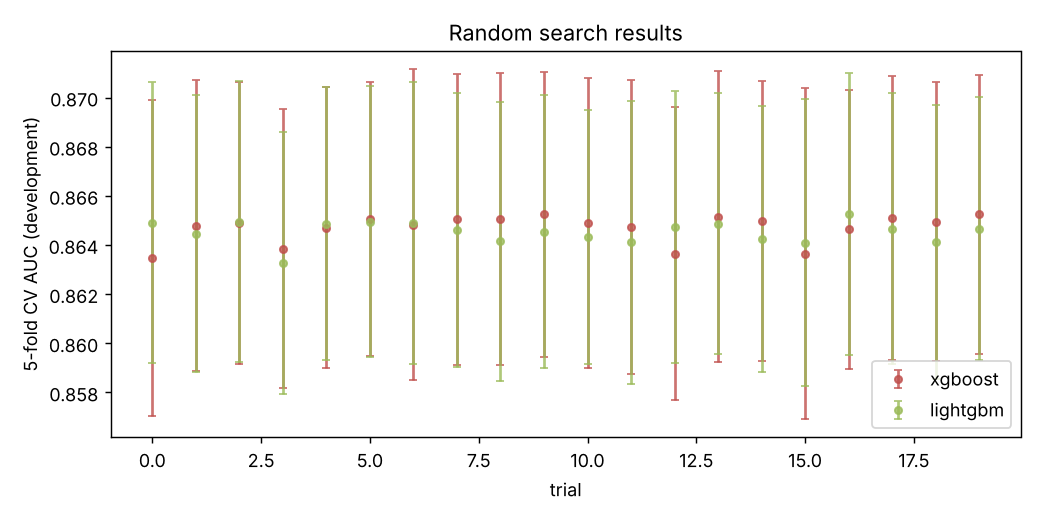

Range of mean CV AUC across trials: {'xgboost': np.float64(0.0018), 'lightgbm': np.float64(0.002)}


In [8]:
display(Image(cmp.plot_tuning(cv_results, FIG / "challenger_tuning_cv_auc.png")))
spread = {k: (cv["cv_auc_mean"].max() - cv["cv_auc_mean"].min()) for k, cv in cv_results.items()}
print("Range of mean CV AUC across trials:", {k: round(v, 4) for k, v in spread.items()})

The tree models give the same kind of output as the scorecard: a PD. To compare them on one scale, each PD is
converted to points with the scorecard's own scaling, `Score = Offset + Factor x ln((1 - PD) / PD)`
(600 points at odds 50:1, PDO 20). The scorecard uses rounded points; the tree scores are not rounded.

## Part C - Comparison on the hold-out set

### Decision rule (fixed before evaluation)

In [9]:
pd.Series(cmp.DECISION_RULE, name="value").to_frame()

,value
min_gini_gain,0.03
diff_ci_excludes_zero,True
brier_not_worse,True
rank_ordering_holds,True


A challenger replaces the champion only if **all four** checks pass. The +3 Gini threshold reflects the cost of
moving from a scorecard to a black-box model: harder validation, harder explanation to customers and
regulators, more monitoring. A small gain does not pay for that.

### C1. Discrimination

In [10]:
models = {"scorecard": champion, **challengers}
preds = cmp.collect_predictions(models, dev, hold)
disc = cmp.discrimination_table(preds, y_dev, y_hold, n_boot=500)
disc.round(4)

,model,dev_auc,dev_gini,dev_ks,hold_auc,hold_auc_lo,hold_auc_hi,hold_gini,hold_ks,gini_dev_minus_hold
0,scorecard,0.8585,0.7169,0.5537,0.8596,0.8523,0.8666,0.7192,0.5650,-0.0023
1,xgboost,0.8765,0.7530,0.5933,0.8673,0.8599,0.8740,0.7345,0.5867,0.0185
2,lightgbm,0.8774,0.7548,0.5952,0.8671,0.8597,0.8738,0.7343,0.5848,0.0205


In [11]:
# Paired bootstrap: both models are scored on the SAME resample, so the CI is for the DIFFERENCE.
# Two separate CIs that overlap would not tell us whether the gain is real.
vs = cmp.challenger_vs_champion(preds, y_hold, n_boot=500)
vs.round(4)

,challenger,auc_diff,auc_diff_lo,auc_diff_hi,gini_diff,share_boot_positive
0,xgboost,0.0077,0.0056,0.0095,0.0153,1.0
1,lightgbm,0.0075,0.0054,0.0095,0.0151,1.0


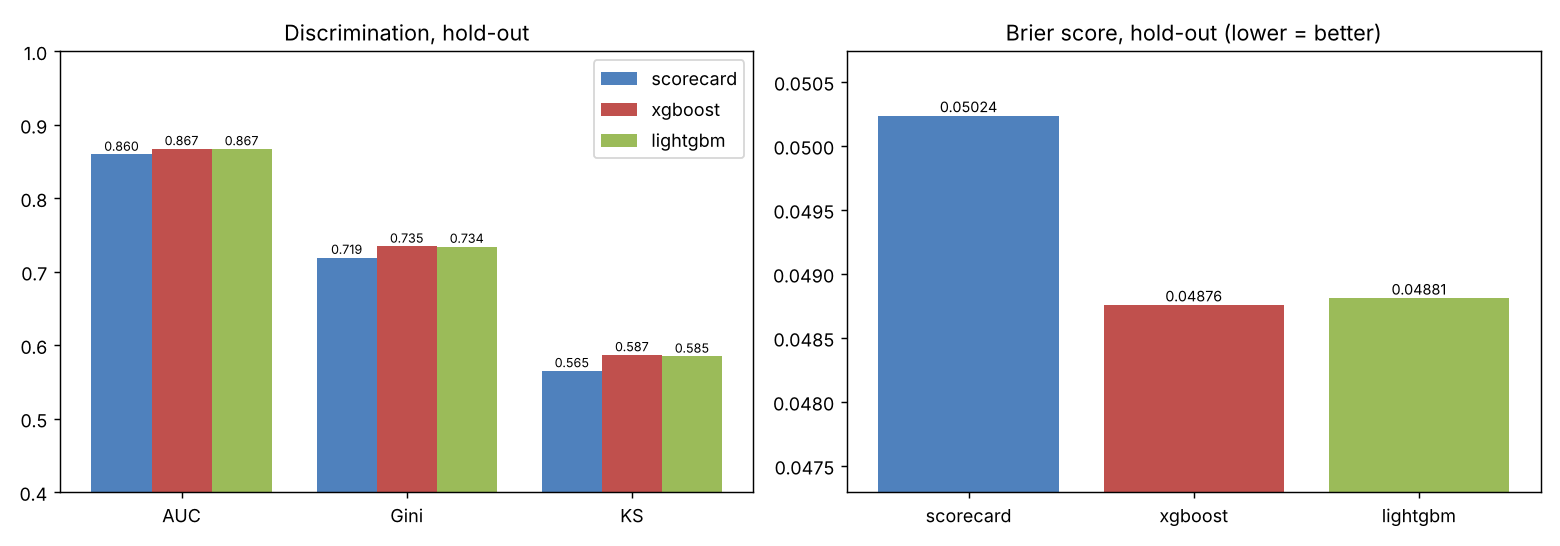

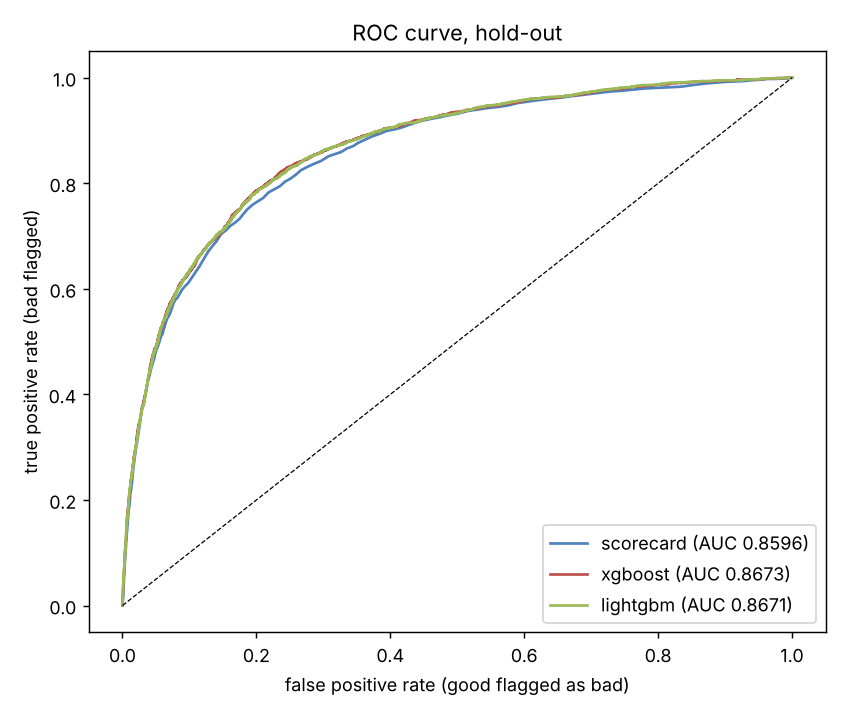

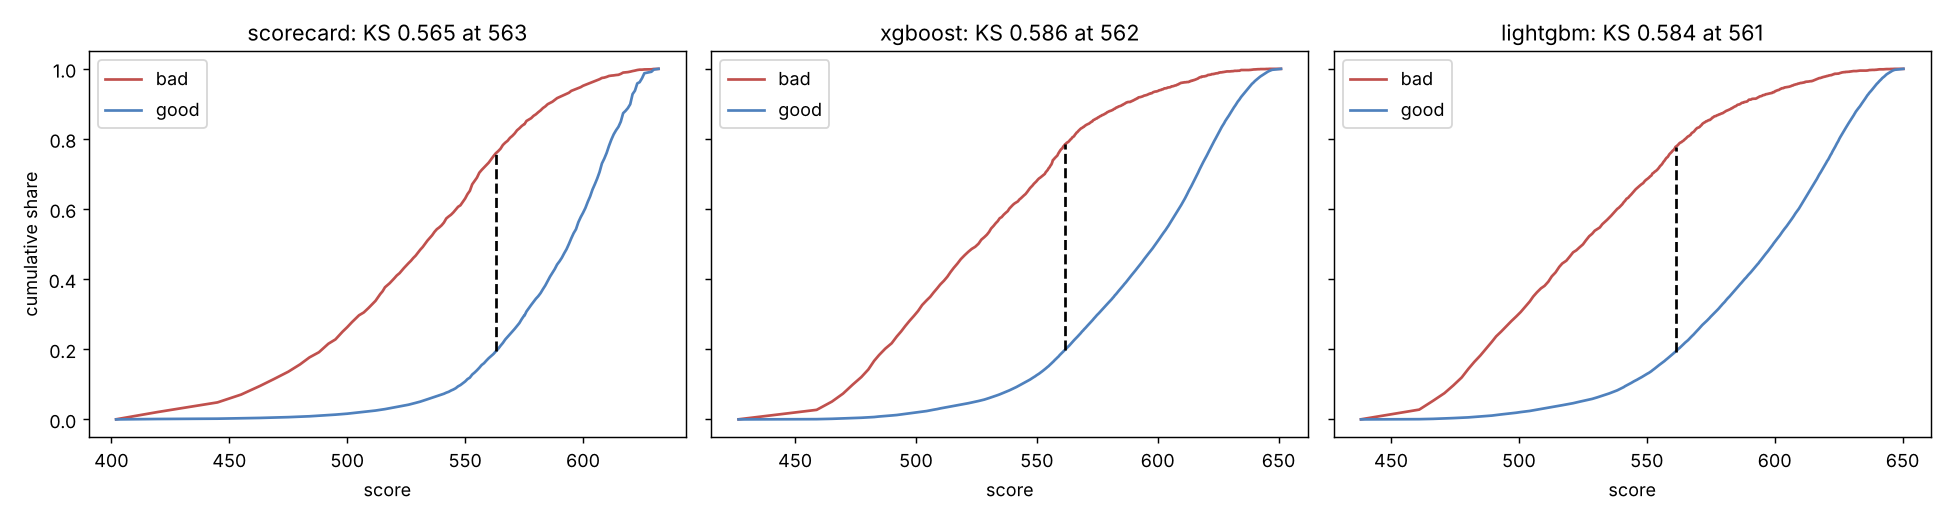

In [12]:
prob = cmp.probability_table(preds, y_hold)
display(Image(cmp.plot_metric_bars(disc, prob, FIG / "challenger_metrics_bar.png")))
display(Image(cmp.plot_roc(preds, y_hold, FIG / "challenger_roc_holdout.png")))
display(Image(cmp.plot_ks(preds, y_hold, FIG / "challenger_ks_holdout.png")))

### C2. Calibration

Ranking is not enough: the PD itself feeds pricing, limits and expected loss. Overall calibration (mean PD vs
bad rate, Brier, log loss, calibration slope) and calibration by grade. Grades are the deciles of each model's
**development** score, applied to the hold-out set.

,model,brier,log_loss,mean_pd,observed_bad_rate,calib_intercept,calib_slope,hl_statistic,hl_p_value
0,scorecard,0.05024,0.18269,0.06641,0.06678,-0.02545,0.98421,56.52042,0.00000
1,xgboost,0.04876,0.17653,0.06792,0.06678,0.01835,1.02212,16.91754,0.07621
2,lightgbm,0.04881,0.17664,0.06781,0.06678,0.01041,1.01683,12.55584,0.24958


observed / predicted,lightgbm,scorecard,xgboost
grade,,,
1,0.661,0.670,0.735
2,0.806,0.618,0.780
3,1.098,0.645,1.078
4,0.876,0.724,0.861
5,0.921,0.684,0.841
6,0.859,0.915,0.865
7,0.869,1.028,0.813
8,1.052,1.051,1.022
9,0.986,1.171,1.019


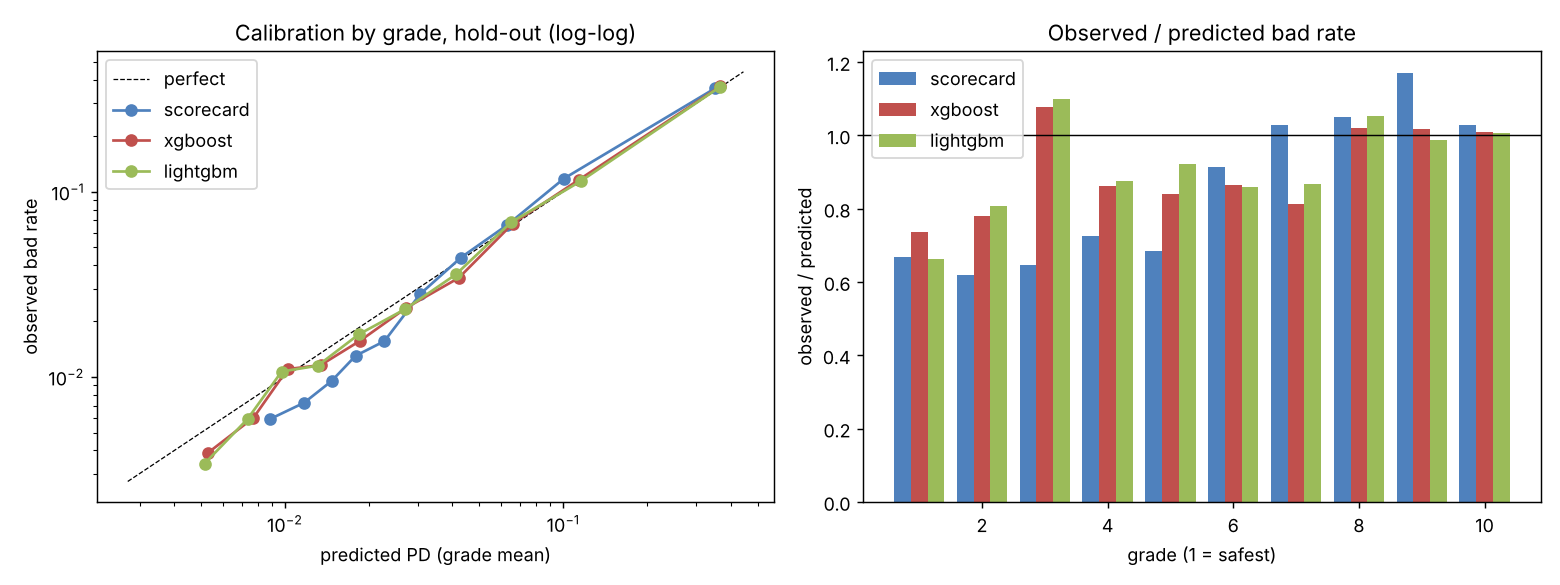

In [13]:
display(prob.round(5))
ro, cal = cmp.grade_tables(preds, y_hold)
display(cal.pivot(index="grade", columns="model", values="ratio_obs_pred").round(3).rename_axis(columns="observed / predicted"))
display(Image(cmp.plot_calibration(cal, FIG / "challenger_calibration_by_grade.png")))

### C3. Rank ordering

Bad rate strictly increasing over 10 grades: {'lightgbm': True, 'scorecard': True, 'xgboost': True}


bad rate %,lightgbm,scorecard,xgboost
grade,,,
1,0.34,0.59,0.39
2,0.59,0.72,0.60
3,1.07,0.95,1.10
4,1.15,1.30,1.16
5,1.70,1.56,1.57
6,2.32,2.80,2.36
7,3.58,4.41,3.42
8,6.83,6.63,6.73
9,11.45,11.79,11.61


number of bads,lightgbm,scorecard,xgboost
grade,,,
1,15,28,17
2,26,33,27
3,48,44,49
4,53,52,53
5,75,77,69
6,104,122,106
7,159,198,157
8,314,292,299
9,526,514,539


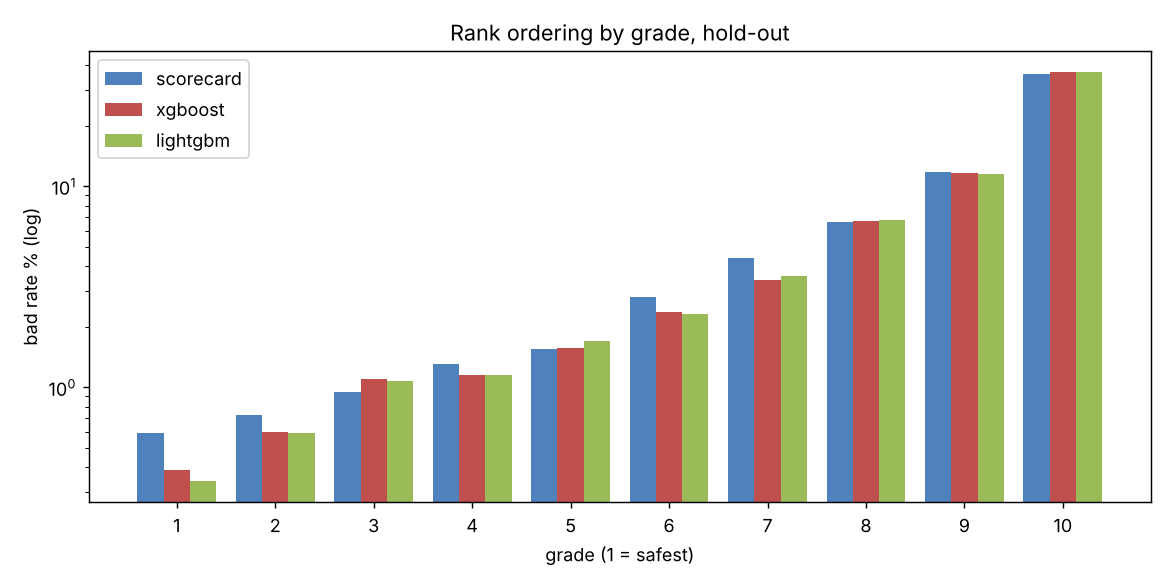

In [14]:
ro_ok = cmp.rank_ordering_ok(ro)
print("Bad rate strictly increasing over 10 grades:", ro_ok)
display(ro.pivot(index="grade", columns="model", values="bad_rate").mul(100).round(2).rename_axis(columns="bad rate %"))
display(ro.pivot(index="grade", columns="model", values="bad").rename_axis(columns="number of bads"))
display(Image(cmp.plot_rank_ordering(ro, FIG / "challenger_rank_ordering.png")))

### C4. Business view: bad rate at the same approval rate

AUC differences are abstract. The question a credit committee asks is: *if we approve the same share of
applicants, how many fewer defaults do we get?* Cut-offs are the development-score quantiles for each target
approval rate, then applied to the hold-out set.

bad rate among approved %,lightgbm,scorecard,xgboost
target_approval,,,
0.5,0.97,1.02,0.96
0.6,1.20,1.31,1.20
0.7,1.54,1.75,1.52
0.8,2.21,2.34,2.17
0.9,3.26,3.36,3.25


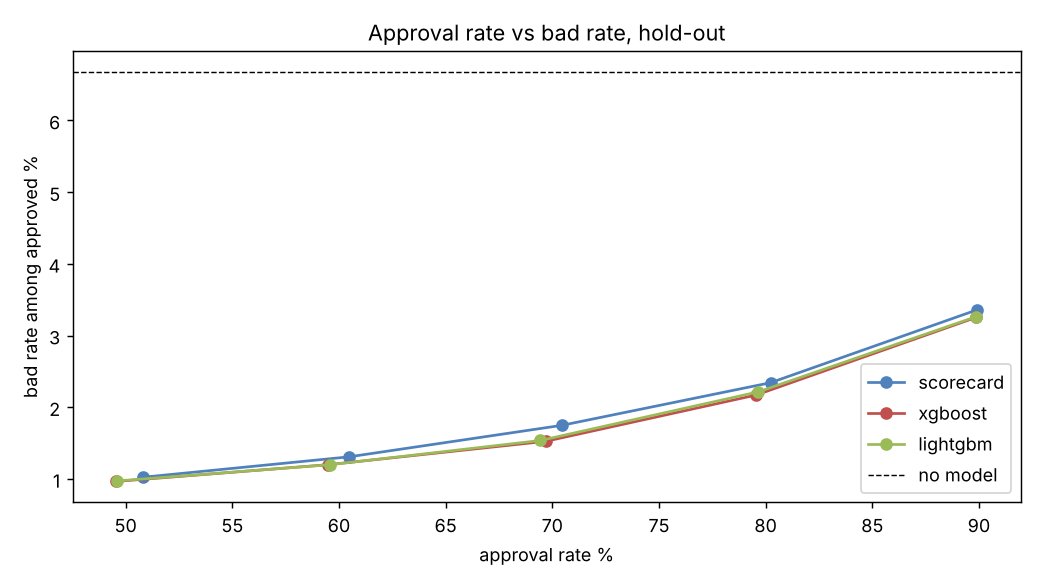

In [15]:
appr = cmp.approval_table(preds, y_hold)
display(appr.pivot(index="target_approval", columns="model", values="bad_rate_approved").mul(100).round(2)
        .rename_axis(columns="bad rate among approved %"))
display(Image(cmp.plot_approval(appr, y_hold, FIG / "challenger_approval_vs_badrate.png")))

### C5. Stability: PSI and CSI

Development vs hold-out. With a random split this mainly confirms the split is clean; it says nothing about
stability over time (no dates in GMSC, see `reports/limitations.md`).

In [16]:
psi_t = cmp.score_psi_table(preds)
csi_t = cmp.csi_table(dev, hold, FEATURES)
display(psi_t.round(5))
display(csi_t.round(5))

,model,score_psi_dev_vs_hold,reading
0,scorecard,0.00046,stable
1,xgboost,0.00034,stable
2,lightgbm,0.00032,stable


,variable,csi,n_buckets,reading
0,age,0.00045,11,stable
1,monthly_income,0.00043,11,stable
2,debt_ratio,0.00041,11,stable
3,revolving_util,0.00024,11,stable
4,n_30_59_late,0.00022,4,stable
5,n_open_lines,0.00021,11,stable
6,n_90_late,0.00018,3,stable
7,n_60_89_late,0.00018,3,stable
8,n_dependents,0.00009,5,stable
9,n_real_estate,0.00005,5,stable


### C6. Explainability: SHAP

SHAP splits each prediction into one contribution per variable, in log-odds of bad. Positive = pushes towards
bad. For the scorecard the same quantity is exact and simple: `coef x (WoE - mean WoE)`, so the three models
can be compared on one scale. A random sample of 5,000 hold-out rows is enough for stable importances.

OK: SHAP values add up to the LightGBM log-odds


,variable,scorecard,xgboost,lightgbm,scorecard_rank,xgboost_rank,lightgbm_rank
0,revolving_util,0.5139,0.7218,0.6178,1,1,1
1,n_30_59_late,0.2297,0.3656,0.3106,2,2,2
2,age,0.2062,0.2157,0.2467,3,4,3
3,n_90_late,0.1515,0.3344,0.1992,6,3,4
4,debt_ratio,0.1785,0.1553,0.1661,4,6,5
5,n_open_lines,0.0159,0.1218,0.1342,9,7,6
6,n_60_89_late,0.0786,0.1648,0.1088,7,5,7
7,n_real_estate,0.1537,0.0922,0.1081,5,8,8
8,monthly_income,NaN,0.0556,0.0589,<NA>,9,9
9,n_dependents,0.0402,0.0283,0.0295,8,10,10


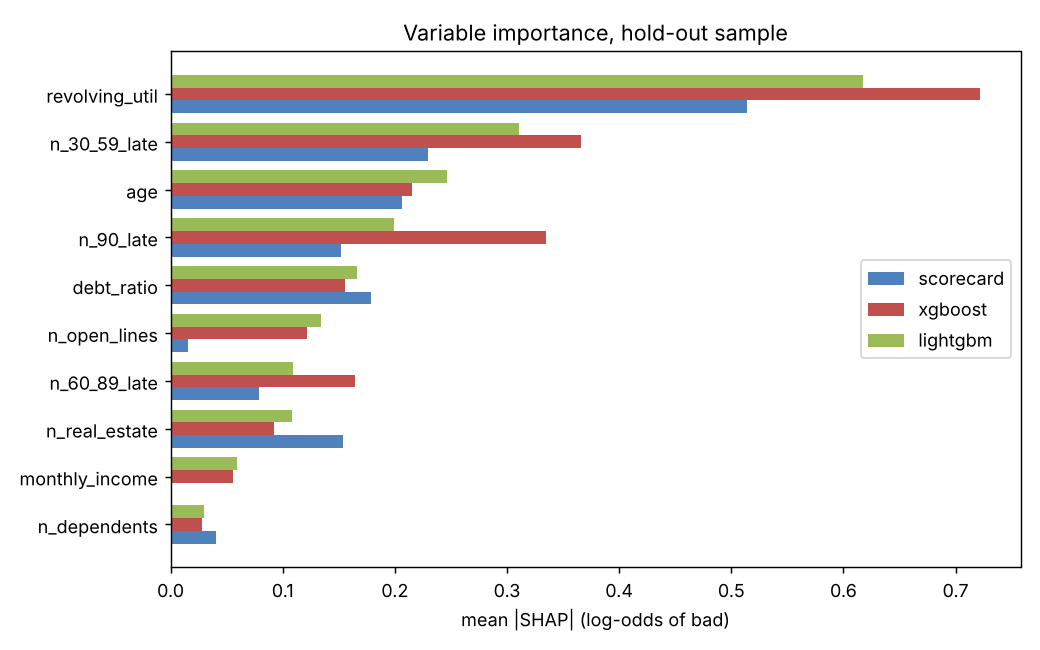

In [17]:
sample = hold.sample(5000, random_state=SEED)
shap_by_model = {"scorecard": (champion.contributions(sample, dev).to_numpy(), champion.features)}
for n in ("xgboost", "lightgbm"):
    shap_by_model[n] = (cmp.tree_shap(challengers[n].model, sample[FEATURES]), FEATURES)

# sanity check: base value + sum of SHAP = model log-odds (LightGBM)
import shap, warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    expl = shap.TreeExplainer(challengers["lightgbm"].model)
p_s = challengers["lightgbm"].predict_pd(sample)
base = np.ravel(expl.expected_value)[-1]
assert np.allclose(base + shap_by_model["lightgbm"][0].sum(1), np.log(p_s / (1 - p_s)), atol=1e-4)
print("OK: SHAP values add up to the LightGBM log-odds")

imp = cmp.shap_importance(shap_by_model)
display(imp.round(4))
display(Image(cmp.plot_shap_importance(imp, FIG / "challenger_shap_importance.png")))

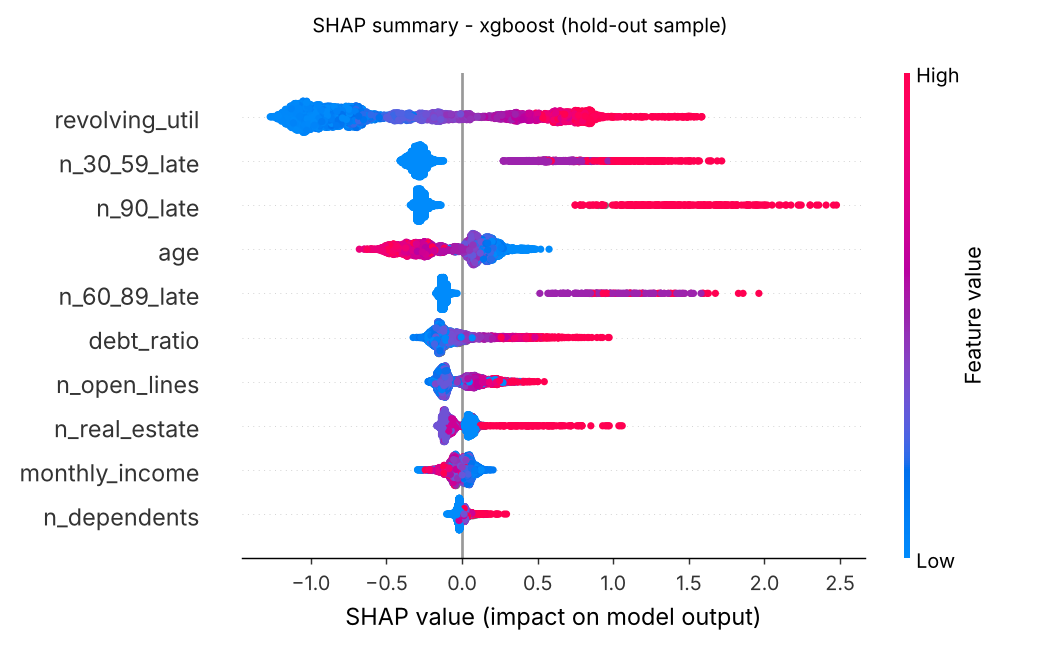

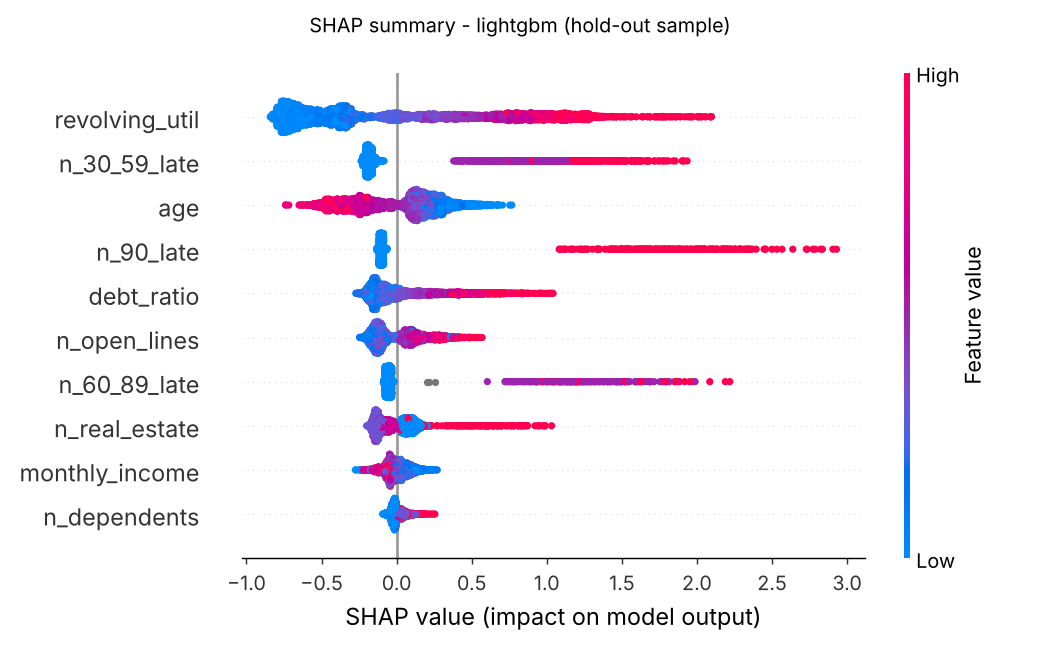

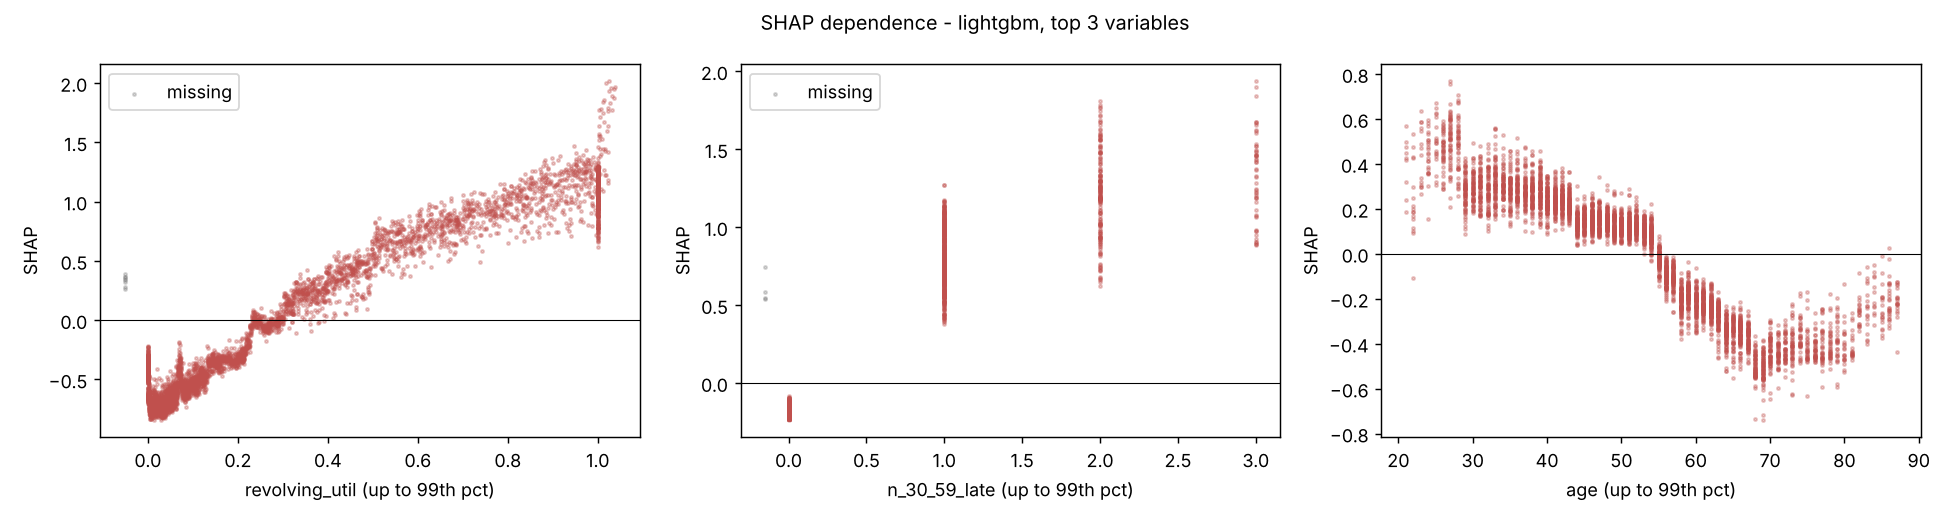

In [18]:
for n in ("xgboost", "lightgbm"):
    sv = shap_by_model[n][0]
    display(Image(cmp.plot_shap_beeswarm(sv, sample[FEATURES], f"SHAP summary - {n} (hold-out sample)",
                                         FIG / f"challenger_shap_beeswarm_{n}.png")))
top3 = list(imp.set_index("variable")["lightgbm"].nlargest(3).index)
display(Image(cmp.plot_shap_dependence(shap_by_model["lightgbm"][0], sample[FEATURES], top3,
                                       "SHAP dependence - lightgbm, top 3 variables",
                                       FIG / "challenger_shap_dependence_lightgbm.png")))

### C7. One applicant, two explanations

What a credit officer would see for a single risky applicant: scorecard points per variable versus the
LightGBM SHAP contributions. This is also what the Streamlit app will show.

In [19]:
i = sample.index[np.argmax(challengers["lightgbm"].predict_pd(sample))]   # riskiest applicant in the sample
row = hold.loc[[i]]
pts = champion.points_breakdown(row).set_index("variable")
j = list(sample.index).index(i)
sh = pd.Series(shap_by_model["lightgbm"][0][j], index=FEATURES, name="lightgbm_shap")
view = pd.concat([row[FEATURES].T.iloc[:, 0].rename("value"), pts["points"].rename("scorecard_points"), sh], axis=1)
print(f"Applicant {i}: actual target = {int(row.target.iloc[0])}")
print(f"  scorecard: score {champion.score(row).iloc[0]:.0f}, PD {champion.predict_pd(row)[0]:.2%}")
print(f"  lightgbm : score {challengers['lightgbm'].score(row).iloc[0]:.0f}, PD {challengers['lightgbm'].predict_pd(row)[0]:.2%}")
view.sort_values("lightgbm_shap", ascending=False).round(3)

Applicant 147067: actual target = 1
  scorecard: score 428, PD 88.59%
  lightgbm : score 444, PD 81.66%


,value,scorecard_points,lightgbm_shap
n_90_late,7.000,18.0,2.003
n_60_89_late,2.000,33.0,0.960
revolving_util,0.988,42.0,0.797
n_30_59_late,2.000,40.0,0.662
debt_ratio,0.996,47.0,0.383
age,31.000,57.0,0.172
monthly_income,3712.000,NaN,0.054
n_dependents,1.000,62.0,0.030
n_real_estate,2.000,66.0,0.021
n_open_lines,7.000,63.0,-0.069


## Part D - Decision

In [20]:
rec = cmp.recommend(disc, vs, prob, ro_ok)
display(rec)
print(cmp.decision_text(rec, disc))

,challenger,gini_gain,check_gini_gain,check_ci_above_zero,check_brier_not_worse,check_rank_ordering,replaces_champion
0,xgboost,0.015317,False,True,True,True,False
1,lightgbm,0.015052,False,True,True,True,False


Keep the scorecard as champion. Best challenger (xgboost) gains +1.5 Gini points but fails: gini_gain. Use it as a benchmark / challenger.


In [21]:
out = "../outputs/metrics/"
disc.to_csv(out + "challenger_discrimination.csv", index=False)
vs.to_csv(out + "challenger_vs_champion.csv", index=False)
prob.to_csv(out + "challenger_probability.csv", index=False)
ro.to_csv(out + "challenger_rank_ordering.csv", index=False)
cal.to_csv(out + "challenger_calibration_by_grade.csv", index=False)
appr.to_csv(out + "challenger_approval.csv", index=False)
psi_t.to_csv(out + "challenger_psi.csv", index=False)
csi_t.to_csv(out + "challenger_csi.csv", index=False)
imp.to_csv(out + "challenger_shap_importance.csv", index=False)
rec.to_csv(out + "challenger_decision.csv", index=False)
for k, cv in cv_results.items():
    cv.to_csv(out + f"challenger_tuning_{k}.csv", index=False)
print("Saved challenger tables to outputs/metrics/ and models to outputs/models/")

Saved challenger tables to outputs/metrics/ and models to outputs/models/


## Conclusions

**1. The challengers rank better, but only a little.** Hold-out AUC 0.867 for both XGBoost and LightGBM versus
0.860 for the scorecard: **+1.5 Gini points**. The paired bootstrap shows the gain is real (95% CI of the AUC gain
about +0.006 to +0.010, positive in every resample), but it is small. In business terms, at an 80% approval rate
the bad rate among approved applicants falls from 2.34% to about 2.2%.

**2. The challengers are better calibrated by grade.** The scorecard over-predicts PD in its safest grades
(the structural issue documented in notebook 07, Hosmer-Lemeshow rejected). The tree models track the observed
bad rate more closely (Hosmer-Lemeshow not rejected; lower Brier score and log loss). This is the clearest
advantage of the challengers, but the scorecard's master scale already fixes grade-level PDs.

**3. The challengers overfit more.** Development to hold-out, they lose about 2 Gini points; the scorecard loses
none. Hyperparameters barely matter: the mean CV AUC varies by only about 0.002 across 20 random trials, which
suggests the ceiling is set by the 10 inputs, not by tuning.

**4. All three models use the same drivers.** SHAP ranks revolving utilization first and the 30-59 days late count
second in every model; age and 90+ days late follow. The tree models also pick up shapes the monotonic scorecard
cannot, for example a U-shape in age at the oldest ages, and they use `monthly_income`, which the scorecard dropped
for a wrong sign.

**5. Rank ordering holds for all three**, but the tree models' grades 3 and 4 differ by less than 0.1 percentage
points (about 50 bads each), so that ordering is fragile.

**Decision.** The gain fails the pre-set +3 Gini threshold, so the **scorecard stays the champion**. XGBoost and
LightGBM are kept as benchmarks: they show that roughly 1.5 Gini points is what flexibility can add on these
inputs, and they are a useful check of the scorecard's calibration. A bigger gain would need richer data
(more variables, raw histories), not a more complex algorithm.

**Limits of this comparison.** Random split only (no out-of-time test), so the extra overfitting of the trees
may matter more on future applicants than shown here. One seed, one split; tree scores are not rounded while
scorecard points are.